Part A: Dataset Preparation and Preprocessing


Akhilon S - 24BAD008
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Image dimensions: (28, 28)


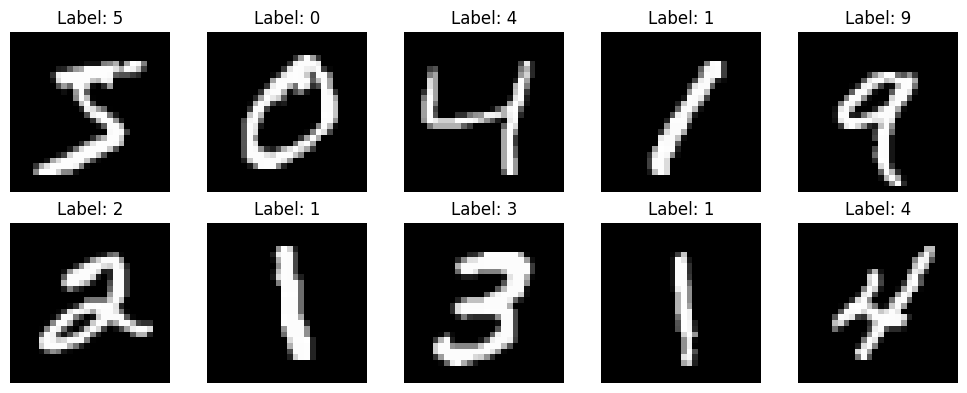

Training data: (60000, 784)
Testing data: (10000, 784)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

print("Akhilon S - 24BAD008")

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Image dimensions:", x_train.shape[1:])

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Part B: Implementing the Encoder and Decoder

In [2]:
print("Akhilon S -24BAD008")

input_dim = 784
latent_dim = 32

input_layer = layers.Input(shape=(input_dim,))

encoded = layers.Dense(128, activation="relu")(input_layer)
encoded = layers.Dense(64, activation="relu")(encoded)
latent = layers.Dense(latent_dim, activation="relu")(encoded)

encoder = Model(input_layer, latent, name="Encoder")

decoder_input = layers.Input(shape=(latent_dim,))
decoded = layers.Dense(64, activation="relu")(decoder_input)
decoded = layers.Dense(128, activation="relu")(decoded)
output_layer = layers.Dense(784, activation="sigmoid")(decoded)

decoder = Model(decoder_input, output_layer, name="Decoder")

autoencoder = Model(input_layer, decoder(encoder(input_layer)), name="Autoencoder")

print("Encoder Summary")
encoder.summary()

print("Decoder Summary")
decoder.summary()

print("Autoencoder Summary")
autoencoder.summary()

Akhilon S -24BAD008
Encoder Summary


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Part C: Compiling and Training the Autoencoder

Akhilon S - 24BAD008
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.2545 - val_loss: 0.1722
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1557 - val_loss: 0.1417
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1369 - val_loss: 0.1289
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1258 - val_loss: 0.1211
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1190 - val_loss: 0.1152
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1145 - val_loss: 0.1112
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1107 - val_loss: 0.1076
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1075 - val_loss: 0.1048
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1049 - val_loss: 0.1025
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1029 - val_loss: 0.1007
Test Reconstruction Loss: 0.10072068870067596


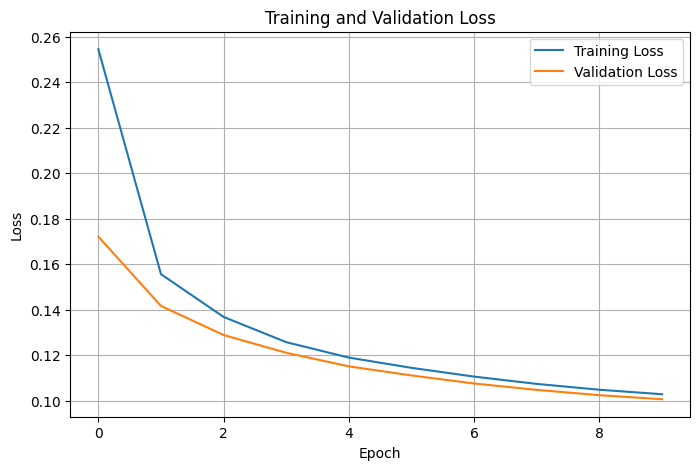

In [3]:
print("Akhilon S - 24BAD008")

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
print("Test Reconstruction Loss:", test_loss)

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

Part D: Dimensionality Reduction, Feature Learning and Reconstruction

Akhilon S - 24BAD008
Original Dimension: 784
Latent Dimension: 32
Latent Features Shape: (10000, 32)


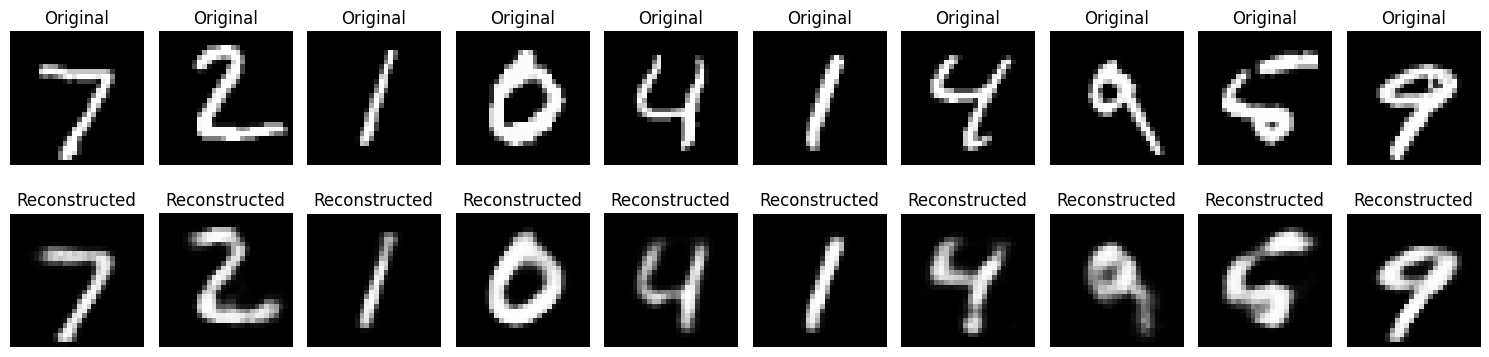

Mean Squared Error: 0.012777725


In [4]:
print("Akhilon S - 24BAD008")

latent_features = encoder.predict(x_test, verbose=0)

print("Original Dimension:", x_test.shape[1])
print("Latent Dimension:", latent_features.shape[1])
print("Latent Features Shape:", latent_features.shape)

reconstructed_images = decoder.predict(latent_features, verbose=0)

n = 10
plt.figure(figsize=(15, 4))

for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

mse = np.mean((x_test - reconstructed_images) ** 2)
print("Mean Squared Error:", mse)

PCA Visualization

Akhilon S - 24BAD008


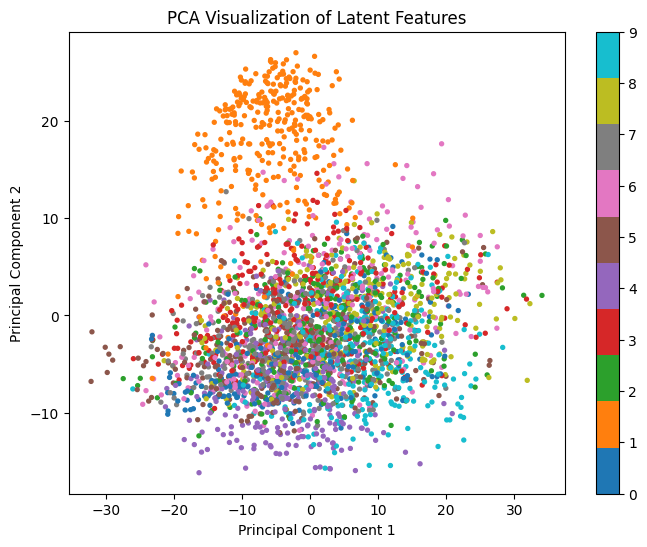

In [5]:
print("Akhilon S - 24BAD008")
from sklearn.decomposition import PCA


num_samples = 3000
latent_2d = PCA(n_components=2).fit_transform(latent_features[:num_samples])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:num_samples],
    cmap="tab10",
    s=8
)
plt.colorbar(scatter, ticks=range(10))
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Latent Features")
plt.show()